# Supplemental Figure 2, Panel H

Scatter plot of feature importance from random forest (mean decrease in impurity, MDI) and ridge regression (regression coefficient, absolute value) for model trained only on enhancer elements (-CTCF, -H3K4me3, TSS-distal; 6h BAFinh @ 10uM)

*Output: PanelH.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(here)
here::i_am("figures/SuppFig2/PanelH/PanelH.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank()))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig2/PanelH

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1  
 [5] dplyr_1.1.4     purrr_1.0.2     readr_2.1.5     tidyr_1.3.1    
 [9] tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    base64enc_0.1-3   

# Load data

In [2]:
#feature importance metrics, model trained on enhancers only, BAFdep from 6h/10uM treatment
data <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "enh_only",
    "dose_10uM", "feature_importance.csv"
  ),
  sep = ","
)

# Generate plot


	Pearson's product-moment correlation

data:  log10(abs(data$Ridge_coef) + 1e-04) and log10(data$MDI_importance + 1e-04)
t = 9.4204, df = 162, p-value < 2.2e-16
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.4859688 0.6856516
sample estimates:
      cor 
0.5949128 


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


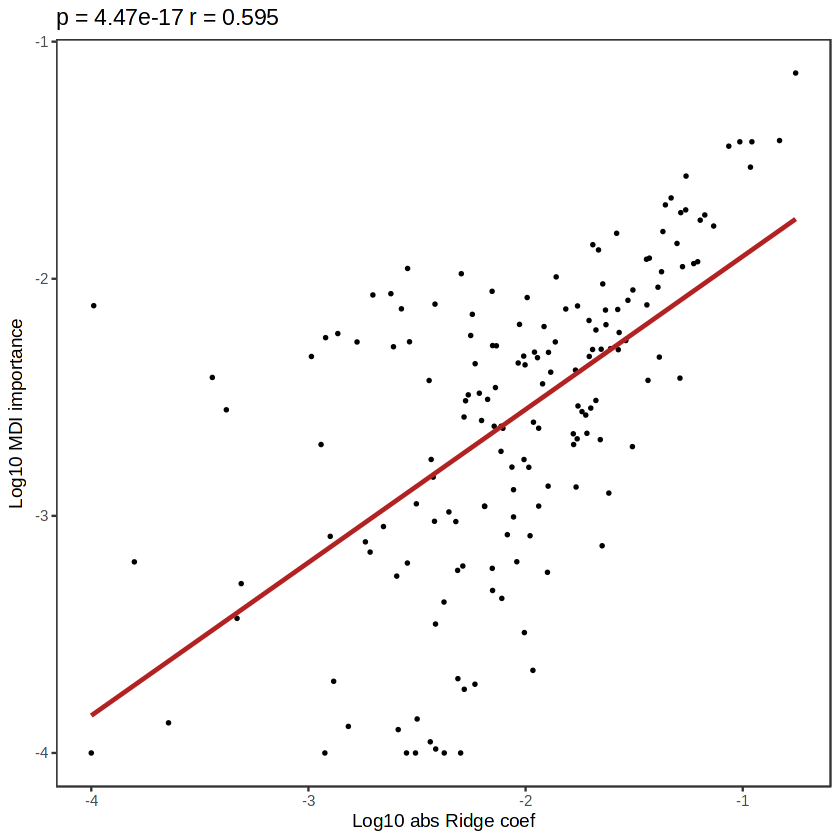

In [3]:
stats <- cor.test(log10(abs(data$Ridge_coef) + 1e-4), log10(data$MDI_importance + 1e-4))
stats

ggplot(data, aes(x=log10(abs(Ridge_coef) + 1e-4), y=log10(MDI_importance + 1e-4))) +
    geom_point(size=.5) +
    geom_smooth(method=lm, se=F, color="firebrick") +
    xlab("Log10 abs Ridge coef") + ylab("Log10 MDI importance") +
    ggtitle(paste("p =", format(stats$p.value, digits=3), "r =", format(stats$estimate, digits=3)))
ggsave("PanelH.pdf", height=3, width=3)